# 05 · Inferencia: Predict Future Sales

**Objetivo:** usar el pipeline completo del notebook 04 (`models/pipeline_completo.pkl`) para predecir las ventas de **noviembre de 2015** (`date_block_num = 34`) de cada par tienda-producto de `test.csv`, un mes que el modelo nunca vio.

No se reentrena nada: el `.pkl` contiene el pipeline de features (con el historial de ventas para calcular los lags), el modelo ganador y el recorte de las predicciones a [0, 20].

**Salida:** `data/processed/predicciones_test.csv`, con las columnas `ID` e `item_cnt_month` (formato de envío de Kaggle).

## Configuración

In [1]:
from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

from future_sales import dataset as ds
from future_sales.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT

pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titleweight"] = "bold"
COLOR, COLOR_ALT = "#2a6f97", "#e07a5f"

with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

2026-11-20 09:07:40.733 | INFO     | future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Proyecto\future-sales


## 1. Carga del pipeline completo

Se carga el `.pkl` y se muestran su estructura y el modelo que contiene.

In [2]:
pipeline_completo = joblib.load(MODELS_DIR / "pipeline_completo.pkl")
pasos = pipeline_completo.regressor_.named_steps
print("Pasos de features:",
      [nombre for nombre, _ in pasos["features"].steps])
print("Modelo:", pasos["modelo"])
print("Recorte de la salida:", pipeline_completo.inverse_func.__name__)
historial = pasos["features"].named_steps["generar_lags"]
print(f"Último mes del historial: {historial.ultimo_mes_}")

Pasos de features: ['mapear', 'generar_lags', 'indicador_faltantes', 'imputar_cero', 'imputar_mediana', 'imputar_categoricas', 'imputar_codigos', 'agrupar_raras', 'one_hot', 'media_target', 'recortar_lags', 'winsorizar', 'log1p', 'eliminar', 'escalar']
Modelo: HistGradientBoostingRegressor(early_stopping=False, max_leaf_nodes=15,
                              random_state=42)
Recorte de la salida: recortar_prediccion
Último mes del historial: 33


## 2. Datos de test y controles de entrada

`test.csv` se lee **crudo** desde `RAW_DATA_DIR`, con `ID` como índice. Se le agrega el mes a predecir (`date_block_num = 34`) y se aplica la misma unificación de tiendas del EDA (no cambia nada en test, pero protege si llegara un ID duplicado).

Controles antes de predecir: columnas, faltantes, pares repetidos y cobertura de tiendas y productos en el historial.

In [3]:
test = pd.read_csv(ds.RAW_DATA_DIR / "test.csv", index_col="ID")
X_test = test.assign(
    date_block_num=ds.MES_TEST,
    shop_id=ds.unificar_tiendas(test["shop_id"]),
)[["date_block_num", "shop_id", "item_id"]]

assert X_test.notna().all().all(), "Hay faltantes en test"
assert not X_test.duplicated(["shop_id", "item_id"]).any(), "Pares repetidos"
assert historial.ultimo_mes_ == ds.MES_TEST - 1, "El historial no llega al mes 33"

mensual = historial.historial
pares = set(zip(mensual["shop_id"], mensual["item_id"]))
con_historial = pd.Series(
    [par in pares for par in zip(X_test["shop_id"], X_test["item_id"])],
    index=X_test.index)
item_visto = X_test["item_id"].isin(mensual["item_id"])
X_test_grupo = np.select([con_historial, item_visto],
                         ["par con historial", "producto visto en otra tienda"],
                         "producto nuevo")
print(f"Filas: {len(X_test):,} | tiendas: {X_test['shop_id'].nunique()} | "
      f"productos: {X_test['item_id'].nunique():,}")
pd.Series(X_test_grupo).value_counts().to_frame("filas")

Filas: 214,200 | tiendas: 42 | productos: 5,100


,filas
par con historial,111471
producto visto en otra tienda,87483
producto nuevo,15246


## 3. Predicción

La salida del pipeline ya está en la escala del target y recortada a [0, 20]. Controles de calidad: una predicción por fila, sin faltantes, todas finitas y dentro del rango.

In [4]:
prediccion = pd.Series(pipeline_completo.predict(X_test), index=X_test.index,
                       name="item_cnt_month")
assert len(prediccion) == len(X_test)
assert prediccion.notna().all() and np.isfinite(prediccion).all()
assert prediccion.between(CFG["RANGO_TARGET"]["min"],
                          CFG["RANGO_TARGET"]["max"]).all()
print("Controles de calidad: OK")
prediccion.describe().to_frame().T

Controles de calidad: OK


,count,mean,std,min,25%,50%,75%,max
item_cnt_month,"214,200.0000",0.2869,0.7883,0.0000,0.0307,0.0866,0.2489,20.0000


## 4. Revisión de las predicciones

Las predicciones deben parecerse a lo que se observó en los meses recientes. Se comparan con las ventas reales de octubre de 2015 (mes 33) de los mismos pares de test:

- la distribución;
- el total de unidades;
- la predicción media por grupo de cobertura.

En el EDA, noviembre vendió 2 % y 10 % más que octubre en 2013 y 2014, pero sobre una tendencia descendente.

,count,mean,std,min,25%,50%,75%,max,total_unidades
octubre_2015_real,"214,200.0000",0.2556,1.0899,0.0000,0.0000,0.0000,0.0000,20.0000,"54,760.0000"
noviembre_2015_pred,"214,200.0000",0.2869,0.7883,0.0000,0.0307,0.0866,0.2489,20.0000,"61,456.4511"


Total predicho vs octubre: +12.2%


octubre             prediccion            
                                 mean         sum       mean         sum
grupo                                                                   
par con historial              0.4912 54,760.0000     0.3848 42,890.5070
producto nuevo                 0.0000      0.0000     0.8086 12,327.8370
producto visto en otra tienda  0.0000      0.0000     0.0713  6,238.1072

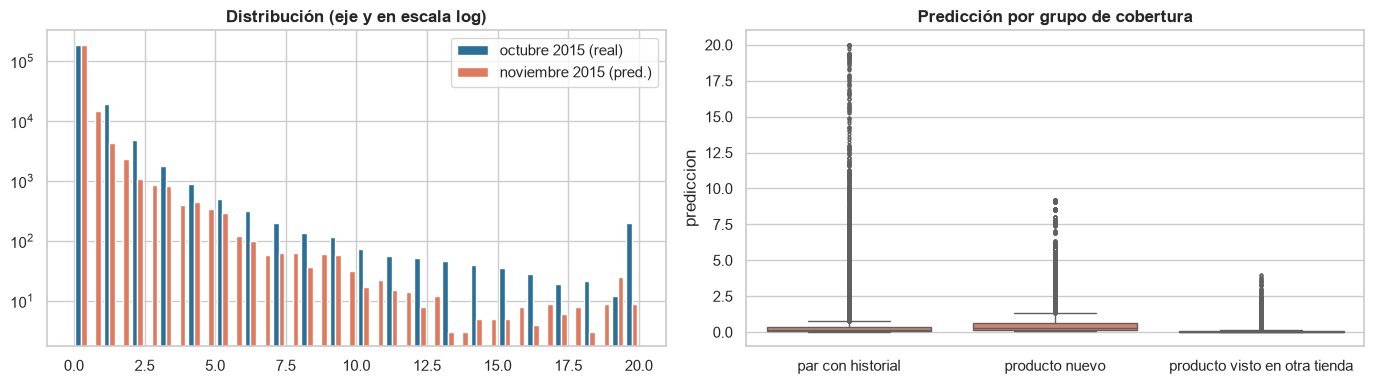

In [5]:
real_33 = (mensual[mensual["date_block_num"] == 33]
           .groupby(["shop_id", "item_id"])["item_cnt_month"].sum())
octubre = pd.Series(
    real_33.reindex(pd.MultiIndex.from_frame(X_test[["shop_id",
                                                     "item_id"]]))
    .fillna(0).to_numpy(), index=X_test.index)
octubre = ds.recortar_target(octubre)

comparacion = pd.DataFrame({
    "octubre_2015_real": octubre.describe(),
    "noviembre_2015_pred": prediccion.describe(),
}).T
comparacion["total_unidades"] = [octubre.sum(), prediccion.sum()]
display(comparacion)
print(f"Total predicho vs octubre: {prediccion.sum() / octubre.sum() - 1:+.1%}")

por_grupo = pd.DataFrame({"grupo": X_test_grupo, "octubre": octubre,
                          "prediccion": prediccion})
display(por_grupo.groupby("grupo")[["octubre", "prediccion"]]
        .agg(["mean", "sum"]))

fig_distribucion, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].hist([octubre, prediccion], bins=40, range=(0, 20), log=True,
             color=[COLOR, COLOR_ALT],
             label=["octubre 2015 (real)", "noviembre 2015 (pred.)"])
ejes[0].set_title("Distribución (eje y en escala log)")
ejes[0].legend()
sns.boxplot(x=por_grupo["grupo"], y=por_grupo["prediccion"], ax=ejes[1],
            color=COLOR_ALT, flierprops={"markersize": 2})
ejes[1].set_title("Predicción por grupo de cobertura")
ejes[1].set_xlabel("")
plt.tight_layout()
plt.show()

**Lectura de las predicciones**

- **Volumen:** el total predicho para noviembre es 12 % mayor que lo vendido en octubre por los mismos pares. Es coherente con el EDA: noviembre vendió 2 % y 10 % más que octubre en 2013 y 2014.
- **Distribución:** como en los datos reales, casi todas las predicciones son cercanas a 0 (mediana de 0.09). El modelo predice valores **suavizados** (pocas predicciones exactamente en 0 o muy altas), que es lo esperado al minimizar el RMSE: ante la incertidumbre, conviene predecir un valor intermedio.
- **Por grupo de cobertura:**
  - **par con historial** (52 % de test): predicción media de 0.38, algo menor que octubre (0.49), porque varios de esos productos ya van a la baja;
  - **producto visto en otra tienda** (41 %): predicción baja (0.07), porque nunca se vendió en esa tienda;
  - **producto nuevo** (7 %): predicción media más alta (0.81). En el EDA, los productos en su primer mes vendieron más que el resto (0.66 contra 0.27); el modelo lo aprende con la bandera de producto nuevo y la categoría.
- **Limitación:** no se conoce el valor real de noviembre de 2015, así que la calidad solo se puede estimar con la validación del notebook 04 (RMSE de 0.816 a un mes) o con el puntaje público de Kaggle al enviar el archivo.

## 5. Archivo de predicciones

Se guarda con las columnas `ID` e `item_cnt_month`, en el mismo orden de `test.csv`. Se verifica con `assert` que las columnas y los IDs coinciden con `sample_submission.csv`.

In [6]:
envio = prediccion.rename_axis("ID").reset_index()
ejemplo = pd.read_csv(ds.RAW_DATA_DIR / "sample_submission.csv")
assert list(envio.columns) == list(ejemplo.columns)
assert envio["ID"].equals(ejemplo["ID"])

ruta = PROCESSED_DATA_DIR / "predicciones_test.csv"
envio.to_csv(ruta, index=False)
print(f"{ruta.name}: {len(envio):,} filas, "
      f"{ruta.stat().st_size / 1e6:.1f} MB")
envio.head()

predicciones_test.csv: 214,200 filas, 5.4 MB


,ID,item_cnt_month
0,0,0.5174
1,1,0.5364
2,2,1.0450
3,3,0.3457
4,4,3.7678
